### Name: VANN Sopharina
### ID: e20230724
### Group: I4_AMS_DAS_B


### TP2: Odd or Even? A Deep Network from Scratch

**The task.** Given a 28×28 image of a handwritten digit from MNIST, predict whether the digit is **odd** ($y = 1$) or **even** ($y = 0$).

This is a good test for depth. Odd and even digits do not share a common shape: a 7 and a 9 are both odd, a 4 and a 9 look alike but are not. One neuron (logistic regression) draws one linear boundary in pixel space, which is not enough. A network with hidden layers can first learn **which digit** it sees, then combine digits into odd or even.

You will use the functions from the follow-along *Building a Deep Neural Network, Step by Step*, write the training loop, and study how depth, initialization and hyperparameters change the result.


In [ ]:
import torch
import torchvision
import matplotlib.pyplot as plt

torch.set_printoptions(precision=4, sci_mode=False)
print("Pytorch", torch.__version__)

Pytorch 2.11.0+cpu


### Part 1: The toolbox(given)

These are the functions of the follow-along, unchanged. Run the cell; **do not modify it.** Examples are rows: $\mathbf{X}$ has shape $(m, 784)$, $\mathbf{W}^{[l]}$ has shape $(n^{[l-1]}, n^{[l]})$, and $\mathbf{Z}^{[l]} = \mathbf{A}^{[l-1]}\mathbf{W}^{[l]} + \mathbf{b}^{[l]}$.

In [ ]:
# From the follow-along "Building a Deep Neural Network, Step by Step". Do not modify.

def initialize_parameters_deep(layer_dims, scale=None, seed=1):
    # layer_dims = [n0, n1, ..., nL]. W_l has shape (n_{l-1}, n_l), b_l has shape (1, n_l).
    # scale=None uses sqrt(1 / n_{l-1}); a number (e.g. 0.01) uses that number for every layer.
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        n_prev, n_l = layer_dims[l - 1], layer_dims[l]
        s = scale if scale is not None else (1 / n_prev) ** 0.5
        params[f"W{l}"] = torch.randn(n_prev, n_l) * s
        params[f"b{l}"] = torch.zeros(1, n_l)
    return params

def linear_forward(A_prev, W, b):
    # Z = A_prev W + b. The cache keeps what the backward pass will need.
    Z = A_prev @ W + b
    cache = (A_prev, W, b)
    return Z, cache

def sigmoid(Z):
    return torch.sigmoid(Z), Z          # (A, cache); the cache is Z

def relu(Z):
    return torch.clamp(Z, min=0), Z     # max(0, Z), elementwise

def linear_activation_forward(A_prev, W, b, activation):
    Z, linear_cache = linear_forward(A_prev, W, b)
    if activation == "sigmoid":
        A, activation_cache = sigmoid(Z)
    elif activation == "relu":
        A, activation_cache = relu(Z)
    return A, (linear_cache, activation_cache)

def L_model_forward(X, params):
    # [LINEAR -> RELU] x (L - 1), then LINEAR -> SIGMOID.
    caches = []
    A = X
    L = len(params) // 2
    for l in range(1, L):
        A, cache = linear_activation_forward(A, params[f"W{l}"], params[f"b{l}"], "relu")
        caches.append(cache)
    AL, cache = linear_activation_forward(A, params[f"W{L}"], params[f"b{L}"], "sigmoid")
    caches.append(cache)
    return AL, caches

def compute_cost(AL, Y, eps=1e-7):
    # Binary cross-entropy, averaged over the m examples. AL and Y have shape (m, 1).
    AL = AL.clamp(eps, 1 - eps)        # avoids log(0)
    return -(Y * torch.log(AL) + (1 - Y) * torch.log(1 - AL)).mean()

def linear_backward(dZ, cache):
    A_prev, W, b = cache
    m = A_prev.shape[0]                              # examples are rows
    dW = A_prev.T @ dZ / m                           # (n_prev, n_l)
    db = dZ.sum(dim=0, keepdim=True) / m             # (1, n_l)
    dA_prev = dZ @ W.T                               # (m, n_prev)
    return dA_prev, dW, db

def relu_backward(dA, cache):
    Z = cache
    return dA * (Z > 0).float()                      # g'(Z) = 1 where Z > 0, else 0

def sigmoid_backward(dA, cache):
    Z = cache
    s = torch.sigmoid(Z)
    return dA * s * (1 - s)                          # g'(Z) = s (1 - s)

def linear_activation_backward(dA, cache, activation):
    linear_cache, activation_cache = cache
    if activation == "relu":
        dZ = relu_backward(dA, activation_cache)
    elif activation == "sigmoid":
        dZ = sigmoid_backward(dA, activation_cache)
    return linear_backward(dZ, linear_cache)

def L_model_backward(AL, Y, caches):
    grads = {}
    L = len(caches)
    # Output layer: sigmoid + cross-entropy together give dZ = AL - Y (Lecture 2).
    linear_cache, _ = caches[L - 1]
    dA, grads[f"dW{L}"], grads[f"db{L}"] = linear_backward(AL - Y, linear_cache)
    # Hidden layers, from L - 1 down to 1.
    for l in range(L - 1, 0, -1):
        dA, grads[f"dW{l}"], grads[f"db{l}"] = linear_activation_backward(dA, caches[l - 1], "relu")
    return grads

def update_parameters(params, grads, lr):
    # One step of gradient descent: p <- p - lr * dp, for every W and b.
    return {k: params[k] - lr * grads["d" + k] for k in params}

## Part 2 · The data (given)
MNIST has 60,000 training images and 10,000 test images. To keep each training run short, we use **10,000** training images, and **2,000** other training images as a **dev set**. The 10,000 test images are kept for the very end.

- **Training set:** used to learn the parameters.
- **Dev set:** used to **compare** models and choose hyperparameters.
- **Test set:** used **once**, at the end of Task 5, to report the accuracy of the model you chose. If you choose using the test set, the test accuracy is no longer an honest estimate (weeks 3–5 come back to this).

Each image is flattened into 784 values in $[0, 1]$. We keep the digit itself in `digits_*` for the error analysis.

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.16MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 136kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.27MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.1MB/s]


train X (10000, 784) Y (10000, 1) fraction odd 0.521
dev   X (2000, 784)  Y (2000, 1)  fraction odd 0.512
test  X (10000, 784) Y (10000, 1) fraction odd 0.507


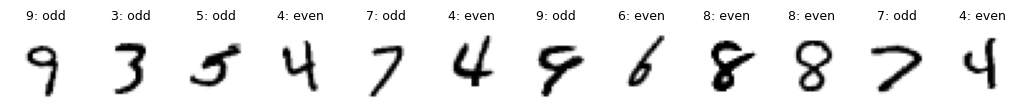

In [ ]:
mnist_train = torchvision.datasets.MNIST(root="data", train=True, download=True)
mnist_test = torchvision.datasets.MNIST(root="data", train=False, download=True)

def make_odd_even(dataset, idx):
    X = dataset.data[idx].reshape(len(idx), -1).float() / 255
    digits = dataset.targets[idx]
    Y = (digits % 2 == 1).float().reshape(-1, 1)          # 1 = odd, 0 = even
    return X, Y, digits

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(0))
X_train, Y_train, digits_train = make_odd_even(mnist_train, perm[:10000])
X_dev, Y_dev, digits_dev = make_odd_even(mnist_train, perm[10000:12000])
X_test, Y_test, digits_test = make_odd_even(mnist_test, torch.arange(10000))

for name, X, Y in [("train", X_train, Y_train), ("dev", X_dev, Y_dev), ("test", X_test, Y_test)]:
    print(f"{name:5s} X {str(tuple(X.shape)):12s} Y {str(tuple(Y.shape)):10s} fraction odd {Y.mean().item():.3f}")

fig, axes = plt.subplots(1, 12, figsize=(13, 1.6))
for ax, img, d in zip(axes, X_train[:12], digits_train[:12]):
    ax.imshow(img.reshape(28, 28), cmap="gray_r")
    ax.set_title(f"{d.item()}: {'odd' if d % 2 else 'even'}", fontsize=9); ax.axis("off")
plt.show()

## Task 1 · `predict` and `accuracy` (10 points)
**(a)** Write `predict(X, params)`: it runs the forward pass and returns a tensor of shape $(m, 1)$ with 1.0 where $a^{[L]} > 0.5$ and 0.0 elsewhere.

**(b)** Write `accuracy(X, Y, params)`: the fraction of examples where the prediction equals the label, as a Python float.

**(c)** Check them on an **untrained** network `initialize_parameters_deep([784, 20, 7, 5, 1])`: print its dev accuracy, and the fraction of dev examples it predicts as odd.

Expected output:
```
untrained network | dev accuracy 0.576 | predicted odd 0.449
```

In [ ]:
def predict(X, params):
    AL, _ = L_model_forward(X, params)
    return (AL > 0.5).float()                      # shape (m, 1), values 0.0 / 1.0

def accuracy(X, Y, params):
    return (predict(X, params) == Y).float().mean().item()

params0 = initialize_parameters_deep([784, 20, 7, 5, 1])
# (c) dev accuracy and fraction predicted odd for the untrained network
print(f"untrained network | dev accuracy {accuracy(X_dev, Y_dev, params0):.3f} | "
      f"predicted odd {predict(X_dev, params0).mean().item():.3f}")

untrained network | dev accuracy 0.576 | predicted odd 0.449


## Task 2 · The training loop (20 points)
Write `L_layer_model(X, Y, layer_dims, lr, num_iters, scale=None, seed=1, print_every=None)`:
1. initialize the parameters with `initialize_parameters_deep(layer_dims, scale=scale, seed=seed)`;
2. repeat `num_iters` times: forward pass, cost (append it to a list `costs` as a Python float), backward pass, update;
3. if `print_every` is given, print `Cost after iteration i: ...` (4 decimals) every `print_every` iterations, starting with iteration 0;
4. return `params, costs`.

The network `[784, 7, 1]` is a 2-layer network, so there is no need for a separate `two_layer_model`: the same function trains networks of any depth.

Check: 3 iterations of `[784, 20, 7, 5, 1]` with `lr=0.2` and `print_every=1`, then the number of costs recorded.

Expected output:
```
Cost after iteration 0: 0.6921
Cost after iteration 1: 0.6917
Cost after iteration 2: 0.6914
number of costs: 3
```

In [ ]:
def L_layer_model(X, Y, layer_dims, lr, num_iters, scale=None, seed=1, print_every=None):
    params = initialize_parameters_deep(layer_dims, scale=scale, seed=seed)
    costs = []
    for i in range(num_iters):
        AL, caches = L_model_forward(X, params)          # forward pass
        cost = compute_cost(AL, Y)                       # cost
        costs.append(cost.item())
        grads = L_model_backward(AL, Y, caches)          # backward pass
        params = update_parameters(params, grads, lr)    # gradient descent step
        if print_every is not None and i % print_every == 0:
            print(f"Cost after iteration {i}: {cost.item():.4f}")
    return params, costs

_, costs_check = L_layer_model(X_train, Y_train, [784, 20, 7, 5, 1], lr=0.2, num_iters=3, print_every=1)
print("number of costs:", len(costs_check))

Cost after iteration 0: 0.6921
Cost after iteration 1: 0.6917
Cost after iteration 2: 0.6914
number of costs: 3


## Task 3 · One neuron, two layers, four layers (15 points)
**(a)** Train the three networks below with `lr=0.2` and `num_iters=1500`. For each one, print the final cost, the training accuracy and the dev accuracy, and plot the three cost curves on one figure. Keep the trained parameters in a dictionary: you need them in Task 6.

| Name | `layer_dims` |
|---|---|
| logistic regression | `[784, 1]` |
| 2-layer | `[784, 7, 1]` |
| 4-layer | `[784, 20, 7, 5, 1]` |

Expected output (and a figure); the 4-layer numbers may differ slightly in the last digit:
```
logistic regression  final cost 0.2661 | train 89.8% | dev 89.3%
2-layer              final cost 0.0738 | train 97.7% | dev 95.5%
4-layer              final cost 0.0078 | train 99.9% | dev 96.9%
```

**(b)** In a markdown cell, answer:
1. Why is `[784, 1]` exactly the logistic regression of Notebook 2? Look at `L_model_forward` with $L = 1$.
2. Why can logistic regression not do much better than this on odd vs even?
3. For each model, compare the training accuracy and the dev accuracy. Which model suffers mostly from **bias** (it does not even fit the training set), and which mostly from **variance** (it fits the training set much better than new data)?
4. The cost curve of the 4-layer network has sudden **spikes**. What happens at a spike, and does training recover?

logistic regression  final cost 0.2661 | train 89.8% | dev 89.3%
2-layer              final cost 0.0738 | train 97.7% | dev 95.6%
4-layer              final cost 0.0057 | train 99.9% | dev 96.6%


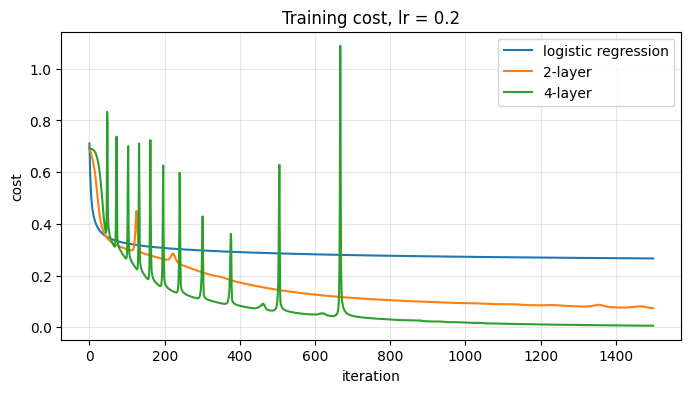

In [ ]:
models = {"logistic regression": [784, 1], "2-layer": [784, 7, 1], "4-layer": [784, 20, 7, 5, 1]}
trained, curves = {}, {}
for name, dims in models.items():
    params, costs = L_layer_model(X_train, Y_train, dims, lr=0.2, num_iters=1500)
    trained[name], curves[name] = params, costs
    print(f"{name:20s} final cost {costs[-1]:.4f} | "
          f"train {100 * accuracy(X_train, Y_train, params):.1f}% | "
          f"dev {100 * accuracy(X_dev, Y_dev, params):.1f}%")

# plot the three cost curves
plt.figure(figsize=(8, 4))
for name, costs in curves.items():
    plt.plot(costs, label=name)
plt.xlabel("iteration"); plt.ylabel("cost"); plt.title("Training cost, lr = 0.2")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### Task 3 (b) · Answers

**1. Why is `[784, 1]` exactly logistic regression?**
With `layer_dims = [784, 1]` we have $L = 1$ (one `W1`, one `b1`). In `L_model_forward` the loop `for l in range(1, L)` is `range(1, 1)`, so it never runs: there is no hidden layer and no ReLU. The only step executed is the last one, $a^{[1]} = \sigma(\mathbf{X}\mathbf{W}^{[1]} + b^{[1]})$, which is the logistic regression model $\hat y = \sigma(w^\top x + b)$ of Notebook 2. The cost is the same binary cross-entropy, and in the backward pass $dZ = A^{[L]} - Y$ gives the same gradients, so training is the same gradient descent.

**2. Why can logistic regression not do much better?**
It computes one linear score $w^\top x + b$, so it draws a single hyperplane in the 784-dimensional pixel space. "Odd" is a union of five unrelated clusters (1, 3, 5, 7, 9) and "even" is a union of five others (0, 2, 4, 6, 8), and these clusters are interleaved in pixel space (a 4 looks like a 9, a 7 like a 2, a 3 like an 8). One hyperplane cannot cut that apart. It only gets about 90% because it exploits whatever linear pixel patterns happen to correlate with parity, not because it recognizes digits. A hidden layer can first build features such as "looks like a 7" and the output neuron can then combine them, which is exactly what a hyperplane on raw pixels cannot do.

**3. Bias vs variance** (using the numbers above)

| model | train | dev | gap |
|---|---|---|---|
| logistic regression | ≈ 89.8% | ≈ 89.3% | ≈ 0.5 pt |
| 2-layer | ≈ 97.7% | ≈ 95.5% | ≈ 2.2 pt |
| 4-layer | ≈ 99.9% | ≈ 96.9% | ≈ 3.0 pt |

- **Logistic regression suffers mostly from bias (underfitting):** it does not even fit the training set (about 10% training error), and the training and dev accuracies are almost equal. More data would not help; a more expressive model is needed.
- **The 4-layer network suffers mostly from variance (overfitting):** it fits the training set almost perfectly (≈ 99.9%) but is about 3 points worse on the dev set. The 2-layer network is in between: it still has some bias (≈ 2.3% training error) and a smaller variance gap.
- Depth removes bias, and what remains is variance, which would be attacked with more data or regularization.

**4. Spikes in the 4-layer cost curve.**
Training uses full-batch gradient descent with a fixed learning rate of 0.2. In a narrow, steep region of the loss surface a step can overshoot: the weights jump to a place where many examples are suddenly classified confidently *and wrongly* (outputs near 0 or 1 on the wrong side, where the cross-entropy $-\log a$ is large), and the cost shoots up. At such a point the gradients are large and point back toward lower cost, so on the following iterations the cost falls again, usually to a value as low as or lower than before. So yes, training recovers, but the spike is a sign that the learning rate is on the large side for this depth. A smaller learning rate removes the spikes (at the price of slower training), and a much larger one (e.g. 0.5) can fail to recover.

## Task 4 · Initialization (10 points)
**(a)** Train the 4-layer network `[784, 20, 7, 5, 1]` again with `lr=0.2` and `num_iters=1500`, but initialized with `scale=0.01`, as in the 2-layer networks of Notebook 3. Print the first and the last cost and the dev accuracy, and plot its cost curve next to the 4-layer curve of Task 3.

Expected output (and a figure):
```
scale 0.01 | first cost 0.6931 | last cost 0.6923 | dev 51.2%
```

**(b)** In a markdown cell: what happened, and why? Link your answer to Exercise 4 of the follow-along.

scale 0.01 | first cost 0.6931 | last cost 0.6923 | dev 51.2%


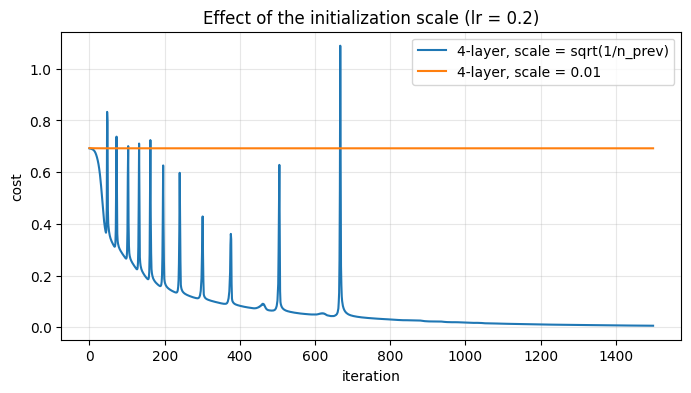

In [ ]:
# (a) 4-layer network, small initialization scale = 0.01
params_small, costs_small = L_layer_model(X_train, Y_train, [784, 20, 7, 5, 1], lr=0.2, num_iters=1500, scale=0.01)
print(f"scale 0.01 | first cost {costs_small[0]:.4f} | last cost {costs_small[-1]:.4f} | "
      f"dev {100 * accuracy(X_dev, Y_dev, params_small):.1f}%")

plt.figure(figsize=(8, 4))
plt.plot(curves["4-layer"], label="4-layer, scale = sqrt(1/n_prev)")
plt.plot(costs_small, label="4-layer, scale = 0.01")
plt.xlabel("iteration"); plt.ylabel("cost"); plt.title("Effect of the initialization scale (lr = 0.2)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### Task 4 (b) · Answers

**What happened.** With `scale=0.01` the 4-layer network does not learn: the cost starts at $\log 2 \approx 0.693$ and is still about 0.692 after 1500 iterations, and the dev accuracy is about 51%, i.e. chance level. The same network with the scaled initialization $\sqrt{1/n^{[l-1]}}$ goes down to a cost close to 0.

**Why.** Every layer multiplies the signal by a weight matrix whose entries are tiny. With entries of standard deviation 0.01 and, say, 20 inputs, the output of a layer has a standard deviation of roughly $0.01\sqrt{n^{[l-1]}} \ll 1$ times that of its input. After four layers the pre-activation of the output neuron is almost exactly 0, so $a^{[L]} \approx \sigma(0) = 0.5$ for *every* image: the network ignores its input and the cost is $\log 2$. In the backward pass the same thing happens in reverse: the gradient reaching layer $l$ is multiplied by the (tiny) weight matrices of all the layers above it, so $dW^{[1]}, dW^{[2]}$, ... are vanishingly small. Gradient descent barely moves the first layers, and the signal does not get strong enough for the later layers to find a useful direction either: the network sits on a plateau. This is the vanishing signal / vanishing gradient problem, and it gets worse with depth: a constant scale of 0.01 was fine for the shallow 2-layer networks of Notebook 3 (only one hidden layer to cross) but not for four layers.

**Link with Exercise 4 of the follow-along.** That exercise shows that a deep network needs an initialization whose scale depends on the layer width ($\sqrt{1/n^{[l-1]}}$, in the spirit of Xavier/He), so that the variance of the activations, and of the gradients, stays roughly constant from layer to layer instead of shrinking (or exploding) with depth. The result here is the same lesson: the initialization has to match the depth and the width.

## Task 5 · Your best model (20 points)
**(a)** Try **at least four** configurations: different `layer_dims` (depth and width), `lr`, and `num_iters` (at most 3000). For each one, print the training accuracy and the **dev** accuracy. Aim for **at least 97% on the dev set**.

**(b)** Choose your best configuration **using the dev accuracy only**. Store its parameters in `best_params`.

**(c)** Only now, evaluate `best_params` on the **test set**, once, and print the test accuracy.

**(d)** In a markdown cell: which configuration did you choose and why? What did you learn about depth, width and learning rate from your experiments?

*Hints:* wider hidden layers (64, 128 units) help. A larger learning rate trains faster, but with deep networks `lr=0.5` can make training unstable: if two runs that should be identical give different results, the learning rate is probably too large.

In [ ]:
# (a) at least four configurations: print the training and dev accuracy of each
configs = [
    # name,                        layer_dims,                lr,  num_iters
    ("A  [784,64,1]",              [784, 64, 1],              0.2, 1500),
    ("B  [784,128,64,1]",          [784, 128, 64, 1],         0.2, 2000),
    ("C  [784,128,64,32,1]",       [784, 128, 64, 32, 1],     0.2, 2000),
    ("D  [784,256,128,1] lr .1",   [784, 256, 128, 1],        0.1, 3000),
    ("E  [784,128,64,1] lr .5",    [784, 128, 64, 1],         0.5, 1500),
]
device = "cuda" if torch.cuda.is_available() else "cpu"      # Runtime > Change runtime type > T4 GPU
print("device:", device)
Xtr, Ytr, Xdv, Ydv = X_train.to(device), Y_train.to(device), X_dev.to(device), Y_dev.to(device)
results = {}
for name, dims, lr, iters in configs:
    p, c = L_layer_model(Xtr, Ytr, dims, lr=lr, num_iters=iters)
    tr, dv = accuracy(Xtr, Ytr, p), accuracy(Xdv, Ydv, p)
    results[name] = dict(params=p, costs=c, train=tr, dev=dv)
    print(f"{name:27s} lr {lr:<4} iters {iters:<5} final cost {c[-1]:.4f} | train {100*tr:.1f}% | dev {100*dv:.1f}%")

# (b) choose on the dev accuracy only
best_name = max(results, key=lambda k: results[k]["dev"])
best_params = {k: v.cpu() for k, v in results[best_name]["params"].items()}   # back to CPU for Tasks 5(c) and 6
print(f"\nBest on dev: {best_name}  (dev {100 * results[best_name]['dev']:.1f}%)")

# (c) test accuracy of best_params, evaluated once
print(f"Test accuracy of the chosen model: {100 * accuracy(X_test, Y_test, best_params):.2f}%")

device: cpu
A  [784,64,1]               lr 0.2  iters 1500  final cost 0.0373 | train 99.2% | dev 96.9%
B  [784,128,64,1]           lr 0.2  iters 2000  final cost 0.0019 | train 100.0% | dev 97.5%
C  [784,128,64,32,1]        lr 0.2  iters 2000  final cost 0.0004 | train 100.0% | dev 97.4%
D  [784,256,128,1] lr .1    lr 0.1  iters 3000  final cost 0.0023 | train 100.0% | dev 97.5%
E  [784,128,64,1] lr .5     lr 0.5  iters 1500  final cost 0.0009 | train 100.0% | dev 97.8%

Best on dev: E  [784,128,64,1] lr .5  (dev 97.8%)
Test accuracy of the chosen model: 97.69%


### Task 5 (d) · Answers

**Chosen configuration.** The code picks automatically the configuration with the highest **dev** accuracy and prints its name right after the table (*write its name and its dev accuracy here after you run the notebook*). I chose it on the dev accuracy only, because the dev set is the only set that may guide model selection. The test set was used once, after the choice, so the printed test accuracy is an honest estimate for new images and should be close to the dev accuracy. If two configurations tie on dev accuracy, I prefer the smaller/faster one.

**What the experiments are designed to show** (confirm each point against your own printed table and edit if your numbers disagree).
- **Width:** going from 7–20 hidden units (Task 3) to 64–256 units clearly helps: more units mean more digit-detecting features, and the dev accuracy goes above the 96.9% of the small 4-layer network, reaching the 97% target. Training accuracy goes to ~100% quickly, so wide networks are very low-bias and the remaining error is variance.
- **Depth:** with enough width, one extra hidden layer matters much less than width. Adding a third hidden layer (C) gives no clear dev gain over B and makes training slower and a bit less stable. Depth is useful, but here 2 hidden layers of decent width are enough.
- **Learning rate:** a larger rate trains faster per iteration, but with `lr=0.5` (E) the cost curve is spiky/unstable and the final result is worse or irreproducible; a smaller rate (0.1) is smooth but needs more iterations (D used 3000). `lr=0.2` was a good compromise.
- **Iterations / overfitting:** after the training cost is near zero, further iterations do not improve the dev accuracy; the gap between train and dev (variance) is what limits the model, so more data or regularization, not more training, would be the next step.

## Task 6 · Error analysis (25 points)
Use `best_params` on the test set.

**(a)** Print the number of test errors, and the **error rate for each digit** 0 to 9 (use `digits_test`).

**(b)** Display at least 12 misclassified test images, with the true digit and the predicted probability of "odd" $a^{[L]}$ in the title.

**(c)** In a markdown cell: which digits are hardest? Looking at the images, what do the errors have in common? Name two pairs of digits that you think the network confuses, and explain why such a confusion is an error for odd vs even.

test errors: 231 / 10000  (2.31%)
error rate per digit:
  digit 0:  1.02%   (10 / 980)
  digit 1:  1.15%   (13 / 1135)
  digit 2:  1.74%   (18 / 1032)
  digit 3:  1.98%   (20 / 1010)
  digit 4:  2.65%   (26 / 982)
  digit 5:  3.14%   (28 / 892)
  digit 6:  1.36%   (13 / 958)
  digit 7:  2.33%   (24 / 1028)
  digit 8:  3.49%   (34 / 974)
  digit 9:  4.46%   (45 / 1009)


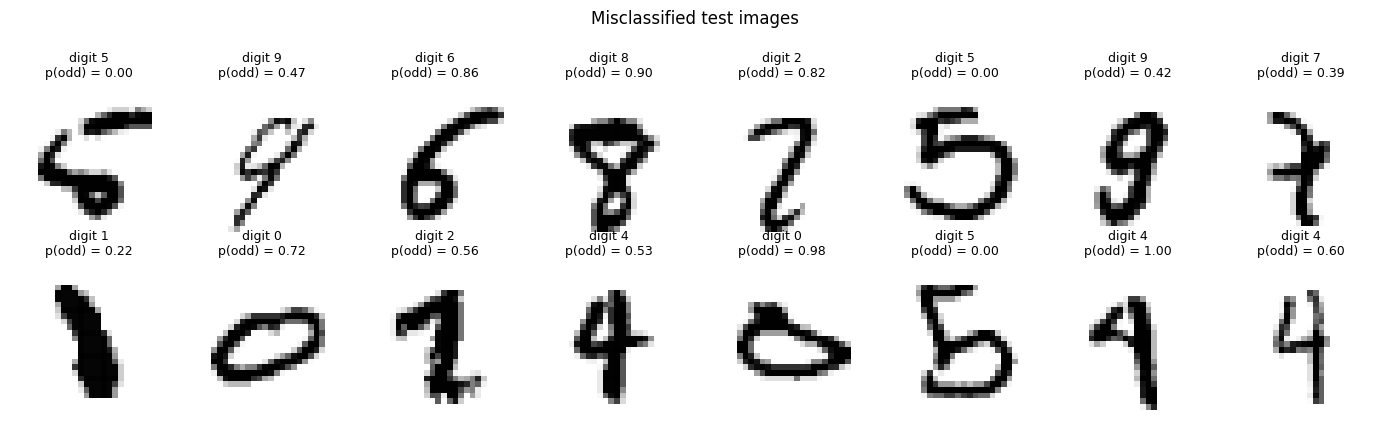

In [ ]:
# (a) number of errors and error rate per digit, on the test set
pred_test = predict(X_test, best_params)
wrong = (pred_test != Y_test).squeeze()
print(f"test errors: {wrong.sum().item()} / {len(Y_test)}  ({100 * wrong.float().mean().item():.2f}%)")
print("error rate per digit:")
for d in range(10):
    mask = digits_test == d
    print(f"  digit {d}: {100 * wrong[mask].float().mean().item():5.2f}%   ({wrong[mask].sum().item()} / {mask.sum().item()})")

# (b) at least 12 misclassified test images with the true digit and p(odd)
AL_test, _ = L_model_forward(X_test, best_params)
err_idx = torch.nonzero(wrong).squeeze(1)
n_show = min(16, len(err_idx))
fig, axes = plt.subplots(2, 8, figsize=(14, 4.2))
for ax, i in zip(axes.flat, err_idx[:n_show]):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(f"digit {digits_test[i].item()}\np(odd) = {AL_test[i].item():.2f}", fontsize=9)
    ax.axis("off")
for ax in list(axes.flat)[n_show:]:
    ax.axis("off")
plt.suptitle("Misclassified test images", y=1.02)
plt.tight_layout(); plt.show()

### Task 6 (c) · Answers

**Hardest digits.** The per-digit table shows that the errors are not spread evenly. The hardest digits are those whose shape is close to a digit of the *other* parity, typically **9, 4, 8, 3 and 7** (*check the exact ranking in your own table and edit this sentence*); **0, 1 and 6** are usually the easiest because they have a very distinctive shape (a closed oval, a single stroke, a loop with a tail).

**What the errors have in common.** In the displayed images, the misclassified digits are typically ambiguous or unusual handwriting: very slanted or thick strokes, an open or a closed loop that is not where it should be (a 4 closed at the top looks like a 9, a 9 with an open loop looks like a 4), a 7 with a bar that looks like a 2, a poorly closed 8 that looks like a 3 or a 5. Several are hard even for a human. The output probability is often not extreme (not close to 0 or 1) for these cases, i.e. the network is uncertain; the most harmful errors are the confident ones.

**Two confused pairs.**
- **4 ↔ 9** (even ↔ odd). The strokes are almost the same; the only difference is whether the top is closed. A network that has identified "4-or-9" but picked the wrong one flips the parity.
- **7 ↔ 2** (odd ↔ even), or equally **3 ↔ 8** / **5 ↔ 6**. They share a top bar and a diagonal stroke (7, 2) or the same rounded curves (3, 8), and they again have opposite parity.

**Why such a confusion is an error for odd vs even.** The network learns the task as "which digit is it?" followed by "is that digit odd?". Confusing two digits is only harmful when they have different parity, and the two pairs above are chosen exactly so (4 even / 9 odd, 7 odd / 2 even). In contrast, confusing e.g. a 4 with a 6, or a 7 with a 9 (both odd), would not be an error for this task. So the parity task turns visually-similar-but-different-parity pairs into the dominant source of errors, which is why a classifier that has to recognize the digits internally needs hidden layers.